# Task 6: Deep SHAP on a Neural Network

**Author:** Yeap Jie Shen (22062548)
**Course:** WQF7009 Explainable Artificial Intelligence, Assignment 1

**Objective:** explain a different black-box model, a multilayer perceptron (MLP), with Deep SHAP (Lundberg & Lee, 2017) and compare it with the improved random forest of [notebook 02](02_shap_rf.ipynb).

**Approach:** same data, split, BMI handling, oversampling, threshold rule, background and main patient (Patient ID 43717) as [notebook 02](02_shap_rf.ipynb#sec-pipelines); only the model and the explainer change.

**Outcome:** `stroke = 1` is a *recorded history* of stroke; model outputs are classification scores, not future stroke risks.

**Contents**
1. [Setup](#sec-setup)
2. [Models](#sec-models)
3. [Model performance](#sec-performance)
4. [Deep SHAP explainer](#sec-explainer)
5. [Local explanation](#sec-local)
6. [Global explanation](#sec-global)
7. [Sanity check: Kernel SHAP](#sec-kernel)
8. [Comparison](#sec-comparison)
9. [Key takeaways](#sec-takeaways)
10. [References](#sec-references)

<a id="sec-setup"></a>

## 1. Setup

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import torch
from matplotlib.text import Text
from matplotlib.ticker import PercentFormatter

from stroke_shap import SEED
from stroke_shap.data import display_label, load_split
from stroke_shap.explain import additivity_residual, deep_shap, importance_by_variable, tree_shap
from stroke_shap.models import (
    evaluate,
    make_mlp,
    make_random_forest,
    out_of_fold_scores,
    select_main_case,
    youden_threshold,
)
from stroke_shap.plotting import COLORS, FIGURE_WIDTH, force_plot, save_figure, set_theme

set_theme()
BACKGROUND_SIZE = 100
KERNEL_PATIENTS = 50

<a id="sec-models"></a>

## 2. Models

| Step | Improved random forest ([notebook 02](02_shap_rf.ipynb)) | MLP |
|---|---|---|
| Data | improved pipeline: training-median BMI + `bmi_missing` flag, same split | same |
| Scaling | none | standardised with training-set mean and SD |
| Class imbalance | `RandomOverSampler`, training data only | same |
| Model | 100 trees, defaults | 22 → 32 → 16 → 1, ReLU, dropout 0.2, sigmoid output |
| Training | — | Adam (learning rate 0.001, weight decay 0.0001), binary cross-entropy, 20 epochs, batch 128; not tuned |
| Threshold | max Youden's J on 5-fold out-of-fold training scores | same rule |

The MLP is a genuine black box: its output is a composition of three weight matrices and nonlinearities, with no rule or path to read off. It is wrapped as a scikit-learn estimator (`stroke_shap.mlp.TorchMLPClassifier`), so both models share the same pipeline, cross-validation and metrics code.

In [2]:
X_train, X_test, y_train, y_test = load_split("improved")
labels = X_test.columns.map(display_label)
makers = {"Improved Random Forest": make_random_forest, "MLP": make_mlp}

models, thresholds, proba = {}, {}, {}
for name, make in makers.items():
    models[name] = make().fit(X_train, y_train)
    thresholds[name] = youden_threshold(y_train, out_of_fold_scores(make(), X_train, y_train))
    proba[name] = pd.Series(models[name].predict_proba(X_test)[:, 1], index=X_test.index)

pd.Series(thresholds).round(2).to_frame("Tuned Threshold")

,Tuned Threshold
Improved Random Forest,0.09
MLP,0.48


<a id="sec-performance"></a>

## 3. Model performance

Each model at its own tuned threshold, on the same 1,022 test patients (50 strokes).

**Result:**
- **Operating point:** the MLP catches 31 of 50 strokes with 235 false alarms; the forest 29 with 225. Nearly equal.
- **Ranking:** the MLP ranks better: ROC AUC 0.79 vs 0.75, average precision 0.21 vs 0.14.
- **Thresholds** (0.48 vs 0.09) and raw scores are not comparable: the MLP's scores spread over a wider range.

**Implication:** the black box is at least as good as the forest, so explaining it is worthwhile; both remain weak screening tools.

In [3]:
results = pd.DataFrame.from_dict(
    {
        f"{name} (Threshold {thresholds[name]:.2f})": evaluate(y_test, proba[name], thresholds[name])
        for name in models
    },
    orient="index",
)
results.round(2).astype(object).T  # object dtype keeps the counts as integers after transposing

,Improved Random Forest (Threshold 0.09),MLP (Threshold 0.48)
Strokes Caught (TP),29,31
Strokes Missed (FN),21,19
False Alarms (FP),225,235
Correctly Cleared (TN),747,737
Recall,0.58,0.62
Precision,0.11,0.12
F1,0.19,0.2
Balanced Accuracy,0.67,0.69
Accuracy,0.76,0.75
ROC AUC,0.75,0.79


<a id="sec-explainer"></a>

## 4. Deep SHAP explainer

### 4.1 Specification

- **Explainer:** `shap.DeepExplainer` (Deep SHAP), which extends DeepLIFT (Shrikumar et al., 2017). Each layer passes back how much of its output change, relative to a reference input, is due to each of its inputs; chaining these shares from the output to the 22 inputs and averaging over the references approximates SHAP values in one backward pass.
- **Output:** the sigmoid output, i.e. the predicted probability of stroke, the same scale as the forest.
- **Background:** the same 100 training patients as [notebook 02](02_shap_rf.ipynb#sec-explainer), standardised as the network sees them.
- **Explained:** all 1,022 test patients; plots show the original (unscaled) values.

Deep SHAP is exact for linear models but an approximation for nonlinear networks, so it is checked against Kernel SHAP in [Section 7](#sec-kernel).

In [4]:
background = X_train.sample(BACKGROUND_SIZE, random_state=SEED)

start = time.perf_counter()
shap_values, base_value = deep_shap(models["MLP"], X_test, background)
runtime_deep = time.perf_counter() - start

start = time.perf_counter()
shap_values_rf, base_value_rf = tree_shap(models["Improved Random Forest"], X_test, background)
runtime_tree = time.perf_counter() - start

pd.DataFrame(
    {"Base Value": [base_value, base_value_rf], "Runtime, 1,022 Patients (s)": [runtime_deep, runtime_tree]},
    index=["MLP (Deep SHAP)", "Improved Random Forest (TreeExplainer)"],
).round(3)

 99%|===================| 2020/2044 [00:23<00:00]        

,Base Value,"Runtime, 1,022 Patients (s)"
MLP (Deep SHAP),0.302,2.218
Improved Random Forest (TreeExplainer),0.081,22.713


### 4.2 Verification

**Result:**
- **Additivity:** Deep SHAP reconstructs every patient's output to float32 precision (max residual 2.3e-07); TreeExplainer leaves 7 patients off by up to 0.03 ([notebook 02, Section 4.2](02_shap_rf.ipynb#sec-explainer)).
- **Base values** (0.30 vs 0.08) are both averages over the same 100 patients, but the MLP scores them higher. Compare contributions between models by sign and rank, not raw size.

In [5]:
assert shap_values.shape == X_test.shape

residuals = {
    "MLP (Deep SHAP)": additivity_residual(base_value, shap_values, proba["MLP"]),
    "Improved Random Forest (TreeExplainer)": additivity_residual(
        base_value_rf, shap_values_rf, proba["Improved Random Forest"]
    ),
}
pd.DataFrame(
    {
        "Exact (< 1e-6)": {name: (r < 1e-6).sum() for name, r in residuals.items()},
        "Max Residual": {name: f"{r.max():.1e}" for name, r in residuals.items()},
    }
)

,Exact (< 1e-6),Max Residual
MLP (Deep SHAP),1022,2.3e-07
Improved Random Forest (TreeExplainer),1015,3.0e-02


<a id="sec-local"></a>

## 5. Local Explanation: Patient ID 43717

The main patient (Patient ID 43717) of [notebook 02](02_shap_rf.ipynb#sec-local) (same selection rule, applied to the forest): age 57, hypertension, average glucose 212 mg/dL, BMI 44.2, current smoker, recorded stroke.

**Result:**
- **Both models flag the patient:** MLP 0.71 (threshold 0.48), forest 0.16 (threshold 0.09).
- **Same drivers:** age, average glucose and current smoking push up in both. The MLP ranks age first (+0.181), then glucose (+0.139); the forest the reverse (glucose +0.054, age +0.033).
- **Remaining features combined:** slightly up for the MLP (+0.027), slightly down for the forest (−0.025).

**Implication:** this patient's explanation does not depend on the model: high glucose, age 57 and smoking. This is the patient used in the Task 5 slides.

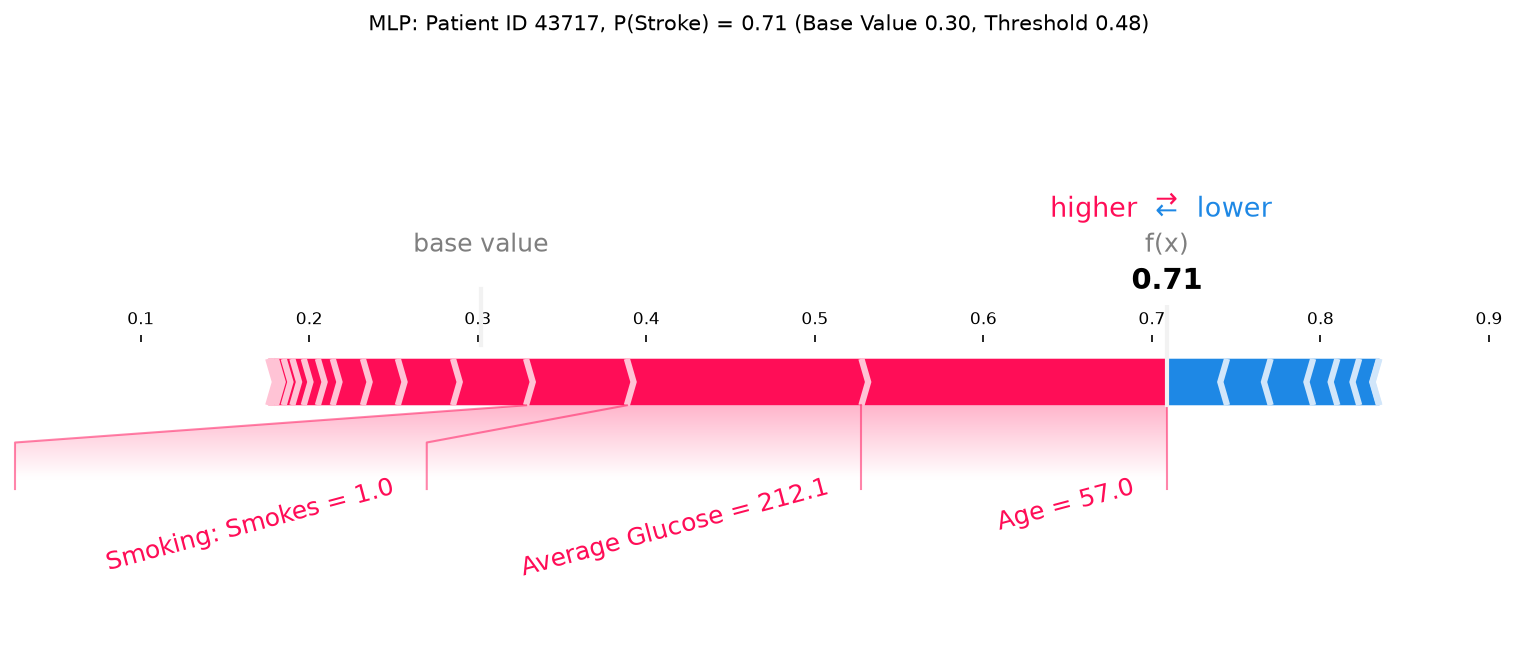

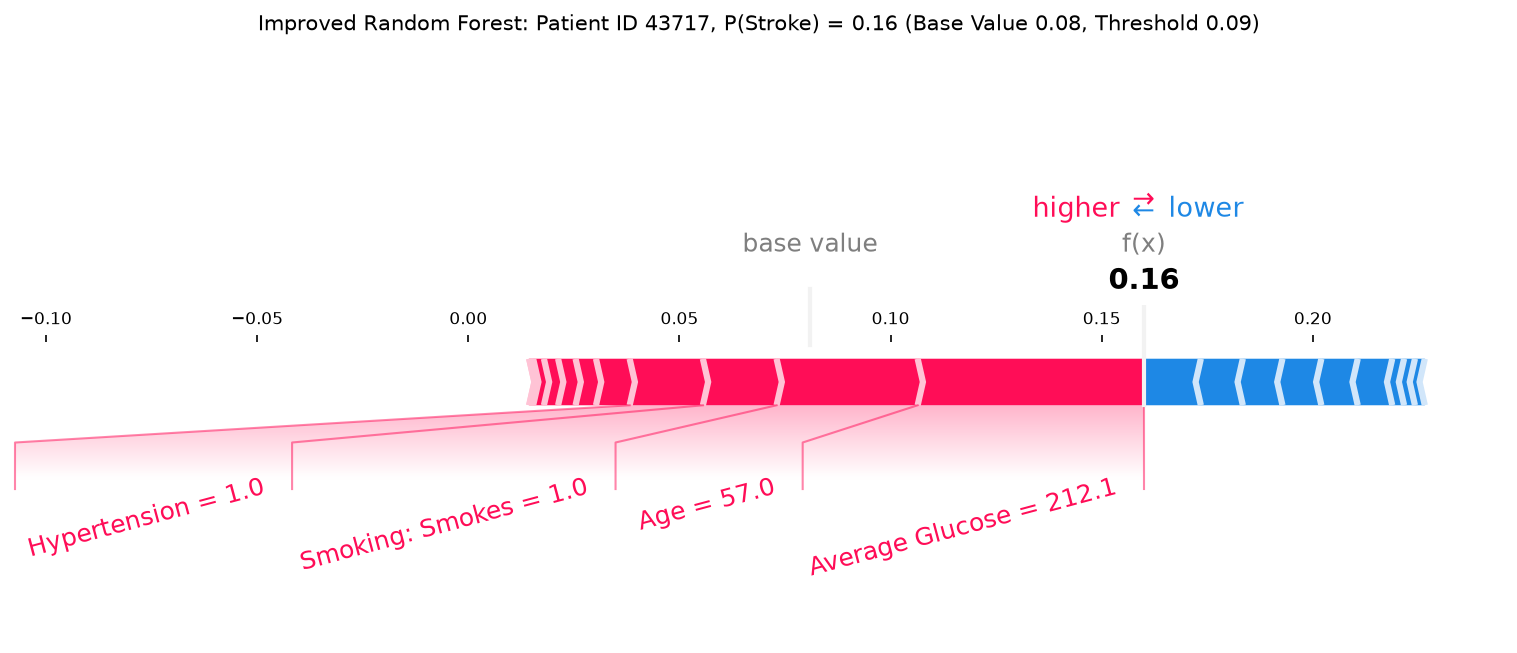

In [6]:
case = select_main_case(
    y_test, proba["Improved Random Forest"], thresholds["Improved Random Forest"], X_test["bmi_missing"]
)
explanations = {"MLP": (shap_values, base_value), "Improved Random Forest": (shap_values_rf, base_value_rf)}

for name, (values, base) in explanations.items():
    fig = force_plot(
        base,
        values.loc[case].to_numpy(),
        X_test.loc[case].set_axis(labels),
        f"{name}: Patient ID {case}, P(Stroke) = {proba[name][case]:.2f} "
        f"(Base Value {base:.2f}, Threshold {thresholds[name]:.2f})",
    )
    save_figure(fig, f"deep_force_case_{'mlp' if name == 'MLP' else 'rf'}")
    plt.show()

In [7]:
contributions = pd.DataFrame(
    {"MLP": shap_values.loc[case], "Improved Random Forest": shap_values_rf.loc[case]}
).set_axis(labels)
top = contributions["MLP"].abs().nlargest(3).index

table = contributions.loc[top].copy()
table.loc["Remaining Features Combined"] = contributions.drop(top).sum()
table.insert(0, "Patient Value", X_test.loc[case].set_axis(labels)[top])
table.round(3)

,Patient Value,MLP,Improved Random Forest
Age,57.00,0.181,0.033
Average Glucose,212.08,0.139,0.054
Smoking: Smokes,1.00,0.060,0.017
Remaining Features Combined,NaN,0.027,-0.025


<a id="sec-global"></a>

## 6. Global explanation

### 6.1 Beeswarm (MLP)

**Result:**
- **Age** dominates with a smooth gradient: young patients (blue) far left, older (red) far right, up to about ±0.6.
- **Risk markers** act in the expected direction: hypertension and current or former smoking push up; never smoked and Unknown push down.
- **BMI Missing** pushes strongly up (up to about +0.5): the MLP also learned the missingness signal ([notebook 02, Section 7.2](02_shap_rf.ipynb#sec-dependence)).
- **Work Type: Children** pushes *up* for children, who also get the most negative age contributions: the network partly offsets its age effect at the youngest ages, so the two must be read together.

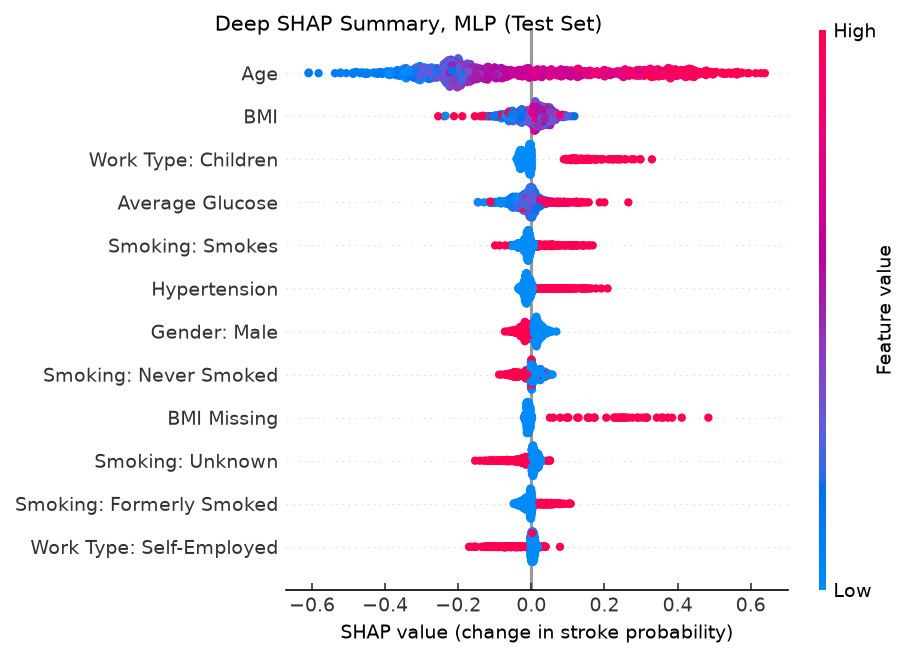

In [8]:
# SHAP calls tight_layout itself, which clashes with the theme's constrained layout
with plt.rc_context({"figure.constrained_layout.use": False}):
    shap.summary_plot(
        shap_values.to_numpy(),
        X_test,
        feature_names=list(labels),
        max_display=12,
        plot_size=(FIGURE_WIDTH, 4.5),
        show=False,
        rng=SEED,
    )
fig = plt.gcf()
for text in fig.findobj(Text):
    text.set_fontsize(9)
fig.axes[0].set_xlabel("SHAP value (change in stroke probability)")
fig.suptitle("Deep SHAP Summary, MLP (Test Set)")
save_figure(fig, "deep_beeswarm")
plt.show()

### 6.2 Importance by variable: improved random forest vs MLP

**Method:** one-hot levels summed per variable, then $\overline{\lvert\phi_j\rvert}$ ([notebook 02, Section 6.1](02_shap_rf.ipynb#sec-global)). The MLP's SHAP values are larger overall, so each model is shown as a share of its own total.

**Result:**
- **Age first in both,** with a larger share for the MLP (47%).
- **Shared top five:** age, smoking, BMI and average glucose. The fifth differs: work type (MLP) vs ever married (forest), both age proxies.
- **Emphasis:** the MLP relies more on age and work type; the forest more on glucose and marital status.

**Implication:** the global pattern (age first, then smoking, glucose and BMI) holds across two very different models; lower ranks differ and should not be over-interpreted.

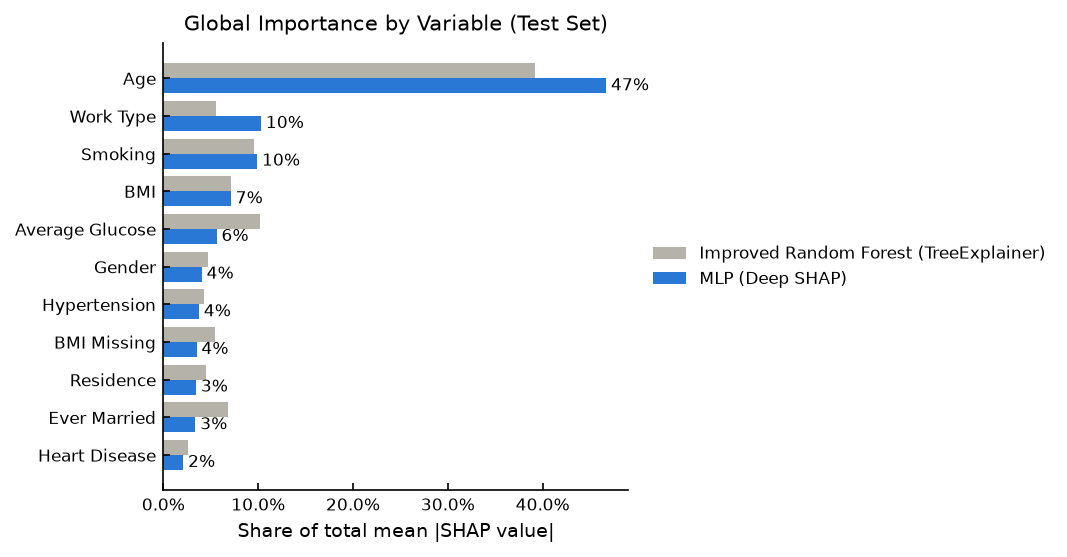

,Improved Random Forest,MLP
Age,0.060,0.235
Work Type,0.009,0.052
Smoking,0.014,0.050
BMI,0.011,0.036
Average Glucose,0.015,0.028


In [9]:
importance = pd.DataFrame(
    {
        "Improved Random Forest": importance_by_variable(shap_values_rf),
        "MLP": importance_by_variable(shap_values),
    }
)
share = (importance / importance.sum()).sort_values("MLP")

fig, ax = plt.subplots(figsize=(FIGURE_WIDTH, 3.6))
y = np.arange(len(share))
ax.barh(
    y + 0.2,
    share["Improved Random Forest"],
    height=0.4,
    color=COLORS["grey"],
    label="Improved Random Forest (TreeExplainer)",
)
ax.barh(y - 0.2, share["MLP"], height=0.4, label="MLP (Deep SHAP)")
for yi, value in zip(y, share["MLP"], strict=True):
    ax.text(value + 0.005, yi - 0.2, f"{value:.0%}", va="center", fontsize=8)
ax.set_yticks(y, share.index)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set(xlabel="Share of total mean |SHAP value|", title="Global Importance by Variable (Test Set)")
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
save_figure(fig, "deep_importance")
plt.show()

importance.sort_values("MLP", ascending=False).head(5).round(3)

<a id="sec-kernel"></a>

## 7. Sanity check: Kernel SHAP

**Question:** does Deep SHAP's fast approximation agree with a model-agnostic estimate?

**Method:** Kernel SHAP (Lundberg & Lee, 2017) treats the MLP as a black box: it evaluates the model on mixtures of the patient's and background values and fits a weighted linear model to recover SHAP values. Same 100 background patients; the main patient (Patient ID 43717) plus 49 random test patients (`random_state=2021`); 2,048 evaluations per patient. Agreement per patient: Pearson's $r$ between its 22 Deep SHAP and 22 Kernel SHAP values, summarised over the 50 patients.

**Result:**
- **Close agreement:** median per-patient $r$ = 0.986 (lowest 0.836); the top feature matches for all 50 patients.
- **Main patient (Patient ID 43717):** largest difference 0.026, small relative to its top contributions (+0.18, +0.14).
- **Largest gap:** 0.113 for one value. Both methods are estimates, so neither is exact ground truth.

In [10]:
scaler, network = models["MLP"].named_steps["standardscaler"], models["MLP"][-1].module_
others = X_test.index.drop(case).to_series().sample(KERNEL_PATIENTS - 1, random_state=SEED)
sample = X_test.loc[[case, *others]]


def predict_scaled(Z: np.ndarray) -> np.ndarray:
    """Return the MLP's stroke probability for standardised rows (the input Kernel SHAP perturbs)."""
    with torch.no_grad():
        return network(torch.as_tensor(Z, dtype=torch.float32)).numpy().ravel()


np.random.seed(SEED)  # Kernel SHAP samples coalitions with NumPy's global generator
start = time.perf_counter()
kernel = shap.KernelExplainer(predict_scaled, scaler.transform(background))
kernel_values = kernel.shap_values(scaler.transform(sample), nsamples=2048, silent=True)
runtime_kernel = time.perf_counter() - start

deep_values = shap_values.loc[sample.index].to_numpy()
correlation = [np.corrcoef(d, k)[0, 1] for d, k in zip(deep_values, kernel_values, strict=True)]
same_top = np.argmax(np.abs(deep_values), axis=1) == np.argmax(np.abs(kernel_values), axis=1)
pd.Series(
    {
        "Patients compared": len(sample),
        "Median correlation per patient": round(np.median(correlation), 3),
        "Lowest correlation": round(np.min(correlation), 3),
        "Same top feature": f"{same_top.sum()} of {len(sample)}",
        "Max |difference|, any value": round(np.abs(deep_values - kernel_values).max(), 3),
        "Max |difference|, main patient": round(np.abs(deep_values[0] - kernel_values[0]).max(), 3),
        f"Kernel SHAP runtime, {len(sample)} patients (s)": round(runtime_kernel, 1),
    }
).to_frame("Value")

,Value
Patients compared,50
Median correlation per patient,0.986
Lowest correlation,0.836
Same top feature,50 of 50
"Max |difference|, any value",0.113
"Max |difference|, main patient",0.026
"Kernel SHAP runtime, 50 patients (s)",2.0


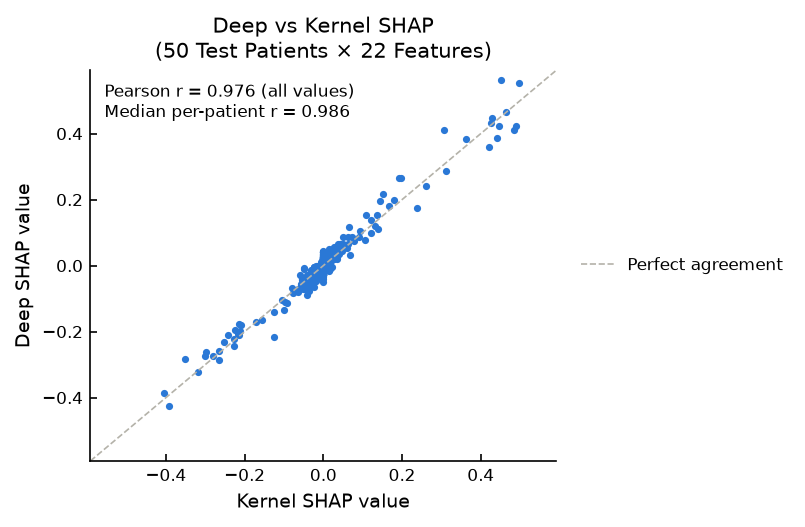

In [11]:
limit = 1.05 * max(np.abs(kernel_values).max(), np.abs(deep_values).max())
fig, ax = plt.subplots(figsize=(FIGURE_WIDTH * 0.75, 3.4))
ax.scatter(kernel_values.ravel(), deep_values.ravel(), s=6)
ax.plot([-limit, limit], [-limit, limit], color=COLORS["grey"], ls="--", lw=0.8, label="Perfect agreement")
ax.set(
    xlabel="Kernel SHAP value",
    ylabel="Deep SHAP value",
    xlim=(-limit, limit),
    ylim=(-limit, limit),
    title="Deep vs Kernel SHAP\n(50 Test Patients × 22 Features)",
)
pooled_r = np.corrcoef(kernel_values.ravel(), deep_values.ravel())[0, 1]
ax.text(
    0.03,
    0.97,
    f"Pearson r = {pooled_r:.3f} (all values)\nMedian per-patient r = {np.median(correlation):.3f}",
    transform=ax.transAxes,
    va="top",
    fontsize=8,
)
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
save_figure(fig, "deep_vs_kernel")
plt.show()

<a id="sec-comparison"></a>

## 8. Comparison

**Result:**
- **Performance:** the MLP ranks better; at the tuned threshold, recall and precision are nearly equal.
- **Explanations agree where it matters:** same top three features for the main case (Patient ID 43717), and age leads globally in both.
- **Explainer trade-off:** Deep SHAP is many times faster (exact runtimes vary between runs) and additive to float precision, but approximate for a nonlinear network; TreeExplainer is exact in theory, though SHAP's interventional routine left small residuals.
- **Limits of Deep SHAP:** it needs a differentiable model and standardised inputs, and treats one-hot columns as continuous.

In [12]:
def top_features(values: pd.DataFrame, n: int) -> str:
    """Return the display names of the main patient's ``n`` largest |SHAP| features, comma-separated."""
    return ", ".join(values.loc[case].abs().nlargest(n).index.map(display_label))


summary = {}
for name, (values, base) in explanations.items():
    metrics = evaluate(y_test, proba[name], thresholds[name])
    score = proba[name][case]
    summary[name] = {
        "Recall / Precision": f"{metrics['Recall']:.2f} / {metrics['Precision']:.2f}",
        "ROC AUC / Average Precision": f"{metrics['ROC AUC']:.2f} / {metrics['Average Precision']:.2f}",
        "Base Value": f"{base:.3f}",
        f"Main Case (Patient ID {case}): Score (Flagged)": f"{score:.2f} ({score >= thresholds[name]})",
        f"Main Case (Patient ID {case}): Top 3 Features": top_features(values, 3),
        "Global Top 5 Variables": ", ".join(importance_by_variable(values).index[:5]),
        "Max Additivity Residual": f"{additivity_residual(base, values, proba[name]).max():.1e}",
    }
summary["MLP"]["Explainer Runtime (s)"] = f"{runtime_deep:.1f}"
summary["Improved Random Forest"]["Explainer Runtime (s)"] = f"{runtime_tree:.1f}"
pd.DataFrame(summary)

,MLP,Improved Random Forest
Recall / Precision,0.62 / 0.12,0.58 / 0.11
ROC AUC / Average Precision,0.79 / 0.21,0.75 / 0.14
Base Value,0.302,0.081
Main Case (Patient ID 43717): Score (Flagged),0.71 (True),0.16 (True)
Main Case (Patient ID 43717): Top 3 Features,"Age, Average Glucose, Smoking: Smokes","Average Glucose, Age, Smoking: Smokes"
Global Top 5 Variables,"Age, Work Type, Smoking, BMI, Average Glucose","Age, Average Glucose, Smoking, BMI, Ever Married"
Max Additivity Residual,2.3e-07,3.0e-02
Explainer Runtime (s),2.2,22.7


<a id="sec-takeaways"></a>

## 9. Key takeaways

1. **The black box is at least as good** ([Section 3](#sec-performance)): ROC AUC 0.79 vs 0.75; 31 vs 29 of 50 strokes caught.
2. **Deep SHAP is fast and consistent** ([Sections 4](#sec-explainer), [7](#sec-kernel)): additive to float precision and close to Kernel SHAP (median correlation 0.986).
3. **Same patient, same story** ([Section 5](#sec-local)): both models flag the main case (Patient ID 43717) because of age, high glucose and smoking.
4. **Age dominates both models** ([Section 6](#sec-global)); smoking, glucose and BMI follow, and age proxies absorb part of the age signal differently in each.
5. **The BMI-missingness signal is in the data, not the model:** the MLP learned it too ([Section 6.1](#sec-global)).

<a id="sec-references"></a>

## 10. References

Lundberg, S. M., & Lee, S.-I. (2017). A unified approach to interpreting model predictions. *Advances in Neural Information Processing Systems, 30*, 4765–4774.

Lundberg, S. M., Erion, G., Chen, H., DeGrave, A., Prutkin, J. M., Nair, B., Katz, R., Himmelfarb, J., Bansal, N., & Lee, S.-I. (2020). From local explanations to global understanding with explainable AI for trees. *Nature Machine Intelligence, 2*(1), 56–67. https://doi.org/10.1038/s42256-019-0138-9

Shrikumar, A., Greenside, P., & Kundaje, A. (2017). Learning important features through propagating activation differences. *Proceedings of the 34th International Conference on Machine Learning, PMLR 70*, 3145–3153.

Youden, W. J. (1950). Index for rating diagnostic tests. *Cancer, 3*(1), 32–35. https://doi.org/10.1002/1097-0142(1950)3:1<32::AID-CNCR2820030106>3.0.CO;2-3